# Project 2: Estimating the models

1. **Baseline model**: multinomial logit on bookings, random-ranking sessions, log position. Identifies $\theta = \beta - \gamma$.
2. **Extended model**: splits $\theta$ into taste $\beta$ and search cost $\gamma$ with two-step simulated least squares on the clicks (PS9).

All results are printed in the **Results** section at the bottom.

In [17]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from itertools import product
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt


from ps8_tools import simulate_search

RES = Path('res'); RES.mkdir(exist_ok=True)

# True: estimate the baseline and run the grid (about half an hour), and save both to res/.
# False: load theta from res/estimates.csv and the grid from res/grid_Q.csv instead.
RUN_GRID = False

# Data

Long format, indexed by $(i, j)$: $i$ is the session (`srch_id`) and $j$ the listing's position in it. Each session also gets a row for the outside option, $j = 0$. $j$ is a label, not a counter.

In [2]:
# All 54 columns take about 9 GB of memory at the peak. These 14 take about 2.5 GB.
# To read everything, set cols = None. Add a column to the list if you need it.
cols = ['srch_id', 'position', 'random_bool', 'click_bool', 'booking_bool', 'price_usd',
        'prop_starrating', 'prop_review_score', 'prop_brand_bool', 'prop_location_score1', 'prop_location_score2',
        'prop_log_historical_price', 'promotion_flag', 'srch_children_count', 'srch_length_of_stay']
dat = pd.read_parquet('train.parquet', columns=cols)

In [4]:
frac = 0.2 # the share of sessions to keep: the full data are slow to estimate on
price_min = dat.groupby('srch_id')['price_usd'].min()
idx_i = price_min.index[price_min > 0] # a few listings have a price of zero, so log price fails: drop their sessions
idx_i = pd.Series(idx_i).sample(frac=frac, random_state=1).values
I_sample = dat['srch_id'].isin(idx_i)
df = dat[I_sample]
df = df.set_index(['srch_id', 'position']).sort_index()
df.index.names = ['i', 'j']
df = df.select_dtypes('number') # numbers only, because the outside rows will be zeros

# the regressors, built before the outside rows go in, so that those rows get zeros
df['log_price'] = np.log(df['price_usd'])
df['stars'] = df['prop_starrating'].astype(float)
df['review'] = df['prop_review_score']
df['zero_stars'] = (df['stars'] == 0).astype(float)   # 1 if the hotel has no star rating (stars = 0)
df['zero_review'] = (df['review'] == 0).astype(float) # 1 if the hotel has no reviews (review = 0); NaN reviews give 0 here
df['position_num'] = df.index.get_level_values('j').astype(float) # Rank_ij
df['position_log'] = np.log(df['position_num']) # log(Rank_ij)
df['constant'] = 1.0

# the outside option: one row per session, j = 0, with every column zero, so delta_i0 = 0
idx_outside = pd.MultiIndex.from_product([df.index.get_level_values('i').unique(), [0]], names=['i', 'j'])
df = df.reindex(df.index.append(idx_outside), fill_value=0).sort_index()

I_outside = df.index.get_level_values('j') == 0
booked_any = df.groupby(level='i')['booking_bool'].transform('max') # 1 if the session booked a hotel
booked_any = booked_any[I_outside]
df.loc[I_outside, 'click_bool'] = 1 # the outside option is always "searched", as in PS8
df.loc[I_outside, 'booking_bool'] = 1 - booked_any # and it is chosen when no hotel is booked

# make random_ bool for outside option = 1 if session is random rank (right now it is 0)
df['random_bool'] = df.groupby(level='i')['random_bool'].transform('max')

assert (df.groupby(level='i')['booking_bool'].sum() == 1).all() # exactly one choice per session

In [5]:
### Random 
# filter on random_bool = 1, i.e. the random ranking subsample
df_rand = df[df['random_bool'] == 1]

# drop the sessions where any hotel has a missing review, and note what is dropped
miss_review = df_rand['review'].isna().groupby(level='i').transform('any')
n_sess, n_rows = df_rand.index.get_level_values('i').nunique(), len(df_rand)
drop_sess = df_rand[miss_review].index.get_level_values('i').unique()
print(f'hotel rows with missing review: {df_rand["review"].isna().sum()}')
print(f'sessions dropped: {len(drop_sess)} of {n_sess} ({len(drop_sess)/n_sess:.1%})')
print(f'rows dropped (incl. outside rows): {miss_review.sum()} of {n_rows} ({miss_review.sum()/n_rows:.1%})')
print(f'bookings in dropped sessions: {df_rand.loc[miss_review & (df_rand.index.get_level_values("j") > 0), "booking_bool"].sum()}')
df_rand = df_rand[~miss_review]
I_chosen_rand = df_rand['booking_bool'] == 1

hotel rows with missing review: 1236
sessions dropped: 911 of 24316 (3.7%)
rows dropped (incl. outside rows): 24055 of 612801 (3.9%)
bookings in dropped sessions: 98


# Functions

`loglike` is the PS9 likelihood with $\gamma = 0$. `price_change` gives the log-price equivalent of moving from position `pos` to `pos-1`. `predict_shares` gives the logit choice probabilities. The rest are for the simulated least squares in the extended model.

In [6]:
def loglike(beta, X, I_chosen):
    '''Minus the average log-likelihood of the logit.'''
    v = X @ beta
    v -= v.groupby(level='i').transform('max') # for numerical stability
    log_probs = v - np.log(np.exp(v).groupby(level='i').transform('sum'))
    return -np.mean(log_probs[I_chosen].values)

### Function that finds price equivalent to a change in position, given the estimated coefficients and the price coefficient.
def price_change(theta, pos):
    delta_pos = np.log(pos-1) - np.log(pos)
    return - theta['position_log']/theta['log_price'] * delta_pos

# predict the shares (choice probabilities) s_j 
def predict_shares(theta, d):
    """
    theta: pd.Series of estimates, indexed by variable name (e.g. pd.Series(res.x, xvars))
    d:     long data with index (i, j), including the outside rows (j = 0)
    returns: pd.Series of s_ij, one per row
    """
    v = d[list(theta.index)].astype(float) @ theta.values          # utility x_ij' theta (outside rows: 0)
    v = v - v.groupby(level='i').transform('max')                  # for numerical stability; shares unchanged
    ev = np.exp(v)
    return ev / ev.groupby(level='i').transform('sum')             # logit share within each session

def gamma_from(gamma_0, gamma_pos):
    """gamma over the columns of X: zero except on the constant and on position_log."""
    gamma = pd.Series(0.0, xvars)
    gamma['constant'], gamma['position_log'] = gamma_0, gamma_pos
    return gamma

def simulated_searches(delta, mu, eps, seed):
    """a_ij^(r): one simulated search dummy for every session and inside option."""
    d_, searched_ = simulate_search(delta, mu, eps, seed=seed)
    I_inside_ = searched_.index.get_level_values('j') > 0 # the outside option is always "searched"
    searched_ = searched_[I_inside_]
    return searched_

def grid_search(X_, theta_, a_data_, eps_draws_):
    """Q(gamma | theta_), eq. (3) in PS9, at every point on the grid, with one simulated data set per element of eps_draws_.
    Conditions on >= 1 search per session, as in the data: a replication only counts for a session if it searched at least one hotel."""
    rows = []
    for g0, gp in tqdm(list(product(g0_grid, gp_grid)), desc=f'grid, R = {len(eps_draws_)}'):
        gamma = gamma_from(g0, gp)
        beta = theta_ + gamma
        a_sim = [simulated_searches(X_ @ beta, X_ @ gamma, eps, seed=3 + r) for r, eps in enumerate(eps_draws_)]
        a_sim = pd.concat(a_sim, axis=1).astype(float) # step 2: one column per replication r
        any_search = a_sim.groupby(level='i').transform('max') # 1 if the session searched any hotel in replication r
        a_bar = (a_sim * any_search).sum(axis=1) / any_search.sum(axis=1) # mean over the replications with >= 1 search
        Q = ((a_data_ - a_bar) ** 2).mean()
        rows.append({'gamma_0': g0, 'gamma_pos': gp, 'Q': Q})
    return pd.DataFrame(rows)

def sim_click_rate(theta_, X_, g0, gp, eps_draws_):
    """Simulated click rate by position at gamma = (g0, gp), conditioning on >= 1 search per session."""
    gamma = gamma_from(g0, gp)
    beta = theta_ + gamma
    a_sim = pd.concat([simulated_searches(X_ @ beta, X_ @ gamma, eps, seed=3 + r)
                       for r, eps in enumerate(eps_draws_)], axis=1).astype(float)
    any_search = a_sim.groupby(level='i').transform('max')
    a_bar = (a_sim * any_search).sum(axis=1) / any_search.sum(axis=1)
    return a_bar.groupby(level='j').mean()

# Baseline model
Random-ranking data, log position.

In [7]:
# chose beta variables to include
xvars = ['log_price', 'stars', 'zero_stars', 'position_log', 'review', 'zero_review', 'prop_brand_bool', 'prop_location_score1', 'promotion_flag', 'constant']
X_rand = df_rand[xvars].astype(float)

if RUN_GRID:
    res_baseline = minimize(loglike, np.zeros(len(xvars)), args=(X_rand, I_chosen_rand), method='BFGS')
    theta_hat = pd.Series(res_baseline.x, xvars)
else:
    theta_hat = pd.read_csv(RES / 'estimates.csv', index_col=0)['theta']
    assert list(theta_hat.index) == xvars, 'xvars have changed since estimates.csv was saved: set RUN_GRID = True'
theta_baseline = theta_hat.round(3)

### Price equivalent and markup
Price equivalent: the price change that keeps the booking probability constant when a hotel moves one position up.
Markup: $\eta_j = p_j \cdot L_j = \frac{p_j}{\alpha(1-s_j)}$

In [8]:
positions = range(2, 26)
dlogp = np.array([price_change(theta_baseline, pos) for pos in positions])

table = pd.DataFrame({
    'Move': [f'{p} → {p-1}' for p in positions],
    'Δ log price': dlogp.round(3),
    'Price increase (%)': (100 * (np.exp(dlogp) - 1)).round(1),
}).set_index('Move')

d = df_rand.copy()                                   # the data you estimated on (with outside rows)

d['s'] = predict_shares(theta_baseline, d)

# checks
hotels = d[d.index.get_level_values('j') > 0].copy()

hotels['markup'] = hotels['price_usd'] / (-theta_baseline['log_price'] * (1 - hotels['s']))

hotels['lerner'] = hotels['markup'] / hotels['price_usd']     # (p − c)/p, ≈ 1/α
hotels['mc']     = hotels['price_usd'] - hotels['markup']      # implied marginal cost

markup_baseline = hotels[['price_usd', 'markup', 'lerner', 'mc']].agg(['mean', 'median']).round(2)

# Extended model
Random-ranking data, log position. Two-step simulated least squares on the clicks to estimate the search costs (demand note p. 45, PS9).

In [9]:
# step 1: theta_hat from the baseline cell (unrounded, theta_baseline is rounded)

X_ext = df_rand[xvars].astype(float) # same X as the baseline, outside rows are zeros
assert not X_ext.isna().any().any(), 'X has missing values: handle them before simulating'

# a_ij: the clicks in the data, inside options only (the outside rows were set to click_bool = 1)
I_inside = X_ext.index.get_level_values('j') > 0
a_data = df_rand.loc[I_inside, 'click_bool'].astype(float)

R = 50 # start small (e.g. R = 2) to check that it runs
rng = np.random.default_rng(7)
eps_draws = [pd.Series(rng.gumbel(size=len(X_ext)), X_ext.index) for r in range(R)] # one draw per (i, j), outside rows included

In [10]:
### Grid over the low-Q region: in getting_started_modified, Q was lowest along the ridge from (2, 0.66) to (3, 0), min at (2.5, 0.33)
# gamma_pos stops just above -theta_pos (= 0.65): beyond it, beta_pos > 0, i.e. consumers would prefer lower positions
g0_grid = [1.75, 2.0, 2.25, 2.5, 2.75, 3.0, 3.25]
gp_grid = [0.0, 0.15, 0.3, 0.45, 0.6, 0.75, 0.9]

if RUN_GRID:
    tab_grid = grid_search(X_ext, theta_hat, a_data, eps_draws)
    tab_grid.to_csv(RES / 'grid_Q.csv', index=False)
else:
    tab_grid = pd.read_csv(RES / 'grid_Q.csv') # computed at the theta in estimates.csv, which is theta_hat here

# the minimum, and the split of theta into taste (beta) and search cost (gamma)
best = tab_grid.loc[tab_grid['Q'].idxmin()]
gamma_0_hat, gamma_pos_hat = best['gamma_0'], best['gamma_pos']
gamma_hat = gamma_from(gamma_0_hat, gamma_pos_hat)
beta_hat = theta_hat + gamma_hat

# save the estimates: theta (baseline), gamma (search cost), beta (taste). Load with pd.read_csv(RES / 'estimates.csv', index_col=0)
pd.DataFrame({'theta': theta_hat, 'gamma': gamma_hat, 'beta': beta_hat}).to_csv(RES / 'estimates.csv')


### Price equivalent and markup (extended model)
The booking probability depends on $\theta = \beta - \gamma$ only, so the total price equivalent is the same as in the baseline; the extended model splits it into taste ($\beta_{pos}$) and search cost ($-\gamma_{pos}$). The price coefficient is the same in both models, so the markup is too.

In [11]:
# price_change(theta, pos) from the simple model: -coef_pos / coef_price * (log(pos-1) - log(pos))
positions = range(2, 26)
coefs = {'Simple logit': theta_hat,                                                      # theta = beta - gamma
         'Taste': beta_hat,                                                          # beta_pos only
         'Search cost': pd.Series({'position_log': -gamma_hat['position_log'],       # -gamma_pos: mu enters with a minus
                                   'log_price': beta_hat['log_price']})}
dlogp_ext = pd.DataFrame({name: [price_change(c, pos) for pos in positions] for name, c in coefs.items()},
                         index=[f'{p} → {p-1}' for p in positions])
dlogp_ext.index.name = 'Move'
assert np.allclose(dlogp_ext['Taste'] + dlogp_ext['Search cost'], dlogp_ext['Simple logit']) # the parts add up in logs

table_ext = (100 * (np.exp(dlogp_ext) - 1)).round(1) # price increase in %

# shares from delta - mu = x' theta, and alpha = -beta_price (= -theta_price)
d_ext = df_rand.copy()
d_ext['s'] = predict_shares(theta_hat, d_ext)
hotels_ext = d_ext[d_ext.index.get_level_values('j') > 0].copy()

alpha_ext = -beta_hat['log_price']
hotels_ext['markup'] = hotels_ext['price_usd'] / (alpha_ext * (1 - hotels_ext['s']))
hotels_ext['lerner'] = hotels_ext['markup'] / hotels_ext['price_usd']

# Export tables to LaTeX

In [12]:
### Export the estimates to LaTeX, in the style of project_one
# three columns: theta from purchases only, and its split into taste (beta) and search cost (gamma).
# gamma is zero on every attribute, so only the constant and log position differ between theta and beta.

LABELS = {'log_price': 'Log price', 'stars': 'Star rating', 'zero_stars': 'No star rating', 'review': 'Review score', 'zero_review': 'No reviews', 'prop_brand_bool': 'Chain',
          'prop_location_score1': 'Location score', 'promotion_flag': 'Promotion', 'position_log': 'Log position', 'constant': 'Constant'}
split = ['position_log', 'constant']
attrs = [k for k in xvars if k not in split] # every estimated coefficient, in the order of xvars
assert set(attrs + split) == set(theta_hat.index) and all(k in LABELS for k in attrs + split), 'a coefficient is missing from the table or LABELS'

gamma_est, beta_est = gamma_hat, beta_hat # the minimum of the grid
fmt = lambda x: f'{x:.3f}'
n_sess = df_rand.index.get_level_values('i').nunique()
n_hotels = int((df_rand.index.get_level_values('j') > 0).sum())

tex = [r'\begin{table}[htbp]', r'\centering', r'\caption{Demand and search cost estimates}', r'\label{tab:search_estimates}',
       r'\begin{tabular}{lccc}', r'\toprule',
       r' & (1) Purchases only & \multicolumn{2}{c}{(2) Purchases and clicks} \\', r'\cmidrule(lr){3-4}',
       r' & $\theta = \beta - \gamma$ & Utility $\beta$ & Search cost $\gamma$ \\', r'\midrule']
tex += [f'{LABELS[k]} & {fmt(theta_hat[k])} & {fmt(beta_est[k])} & \\\\' for k in attrs]
tex.append(r'\midrule')
tex += [f'{LABELS[k]} & {fmt(theta_hat[k])} & {fmt(beta_est[k])} & {fmt(gamma_est[k])} \\\\' for k in split]
tex += [r'\midrule',
        f'Sessions & {n_sess} & \\multicolumn{{2}}{{c}}{{{n_sess}}} \\\\',
        f'Hotel listings & {n_hotels} & \\multicolumn{{2}}{{c}}{{{n_hotels}}} \\\\',
        f'Simulation draws $R$ & & \\multicolumn{{2}}{{c}}{{{len(eps_draws)}}} \\\\',
        r'\bottomrule',
        r'\multicolumn{4}{p{0.9\linewidth}}{\footnotesize \textit{Note:} Random-ranking sessions only, sessions with a missing review score dropped. '
        r'Column (1) is a multinomial logit on bookings, which identifies only $\theta = \beta - \gamma$. '
        r'Column (2) splits $\theta$ with two-step simulated least squares on the clicks: $\gamma$ is chosen on a grid to match the click rates, and $\beta = \hat\theta + \hat\gamma$. '
        r'The simulated click rates are conditioned on at least one search per session, as in the data. '
        r'The search cost loads on the constant and log position only, so the attributes have the same coefficient in $\theta$ and $\beta$.} \\',
        r'\end{tabular}', r'\end{table}']

(RES / 'search_estimates.tex').write_text('\n'.join(tex) + '\n')

1500

# Results

In [13]:
print('Baseline model:', res_baseline.message if RUN_GRID else 'theta loaded from res/estimates.csv')
print('Baseline estimates (theta), random-ranking sample:')
display(theta_baseline.to_frame('theta'))

Baseline model: theta loaded from res/estimates.csv
Baseline estimates (theta), random-ranking sample:


,theta
log_price,-0.754
stars,0.233
zero_stars,0.259
position_log,-0.656
review,0.234
zero_review,-0.090
prop_brand_bool,0.428
prop_location_score1,-0.030
promotion_flag,0.225
constant,-1.873


In [14]:
print('Price equivalent of moving one position up (baseline):')
display(table)
print('Markup (baseline):')
display(markup_baseline)

Price equivalent of moving one position up (baseline):


,Δ log price,Price increase (%)
Move,,
2 → 1,0.603,82.8
3 → 2,0.353,42.3
4 → 3,0.250,28.4
5 → 4,0.194,21.4
6 → 5,0.159,17.2
7 → 6,0.134,14.4
8 → 7,0.116,12.3
9 → 8,0.102,10.8
10 → 9,0.092,9.6


Markup (baseline):


,price_usd,markup,lerner,mc
mean,243.29,323.71,1.33,-80.42
median,128.71,171.41,1.33,-42.68


In [15]:
print('Grid, Q(gamma):')
display(tab_grid.pivot(index='gamma_0', columns='gamma_pos', values='Q').round(5))

Grid, Q(gamma):


gamma_pos,0.00,0.15,0.30,0.45,0.60,0.75
gamma_0,,,,,,
1.75,0.06462,0.05252,0.04795,0.04634,0.04600,0.04630
2.00,0.05577,0.04892,0.04639,0.04560,0.04560,0.04599
2.25,0.05089,0.04701,0.04566,0.04531,0.04548,0.04594
2.50,0.04823,0.04604,0.04533,0.04525,0.04551,0.04603
2.75,0.04683,0.04561,0.04528,0.04538,0.04573,0.04626
3.00,0.04611,0.04548,0.04540,0.04560,0.04604,0.04658


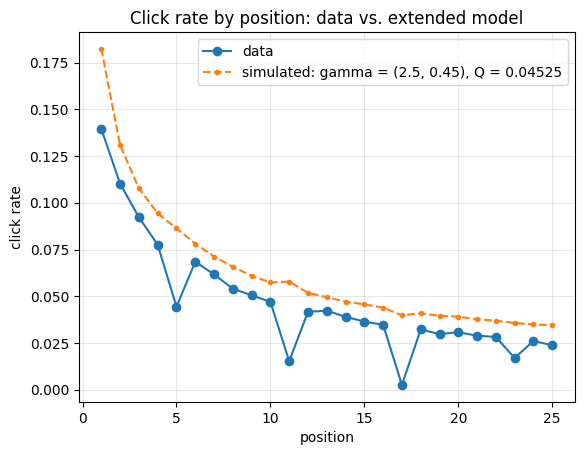

In [19]:
### Click rate by position: data vs. extended model at the grid minimum
click_file = RES / 'click_fit.csv'
if RUN_GRID or not click_file.exists():
    click_sim = sim_click_rate(theta_hat, X_ext, gamma_0_hat, gamma_pos_hat, eps_draws)  # R simulations: about a minute
    click_sim.to_csv(click_file)
else:
    click_sim = pd.read_csv(click_file, index_col=0).squeeze('columns')

a_data.groupby(level='j').mean().loc[1:25].plot(marker='o', label='data')
click_sim.loc[1:25].plot(
    ls='--', marker='.',
    label=f"simulated: gamma = ({gamma_0_hat:g}, {gamma_pos_hat:g}), Q = {best['Q']:.5f}")
plt.xlabel('position'); plt.ylabel('click rate')
plt.title('Click rate by position: data vs. extended model')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(RES / 'click_fit.pdf', bbox_inches='tight')
plt.show()

In [16]:
print('Extended model estimates (grid minimum):')
display(pd.DataFrame({'theta (baseline)': theta_hat, 'gamma (search cost)': gamma_hat, 'beta (taste)': beta_hat}).round(3))

Extended model estimates (grid minimum):


,theta (baseline),gamma (search cost),beta (taste)
log_price,-0.754,0.00,-0.754
stars,0.233,0.00,0.233
zero_stars,0.259,0.00,0.259
position_log,-0.656,0.45,-0.206
review,0.234,0.00,0.234
zero_review,-0.090,0.00,-0.090
prop_brand_bool,0.428,0.00,0.428
prop_location_score1,-0.030,0.00,-0.030
promotion_flag,0.225,0.00,0.225
constant,-1.873,2.50,0.627


In [77]:
print('Price equivalent, % price increase (extended model):')
display(table_ext)
print(f"alpha (extended) = {alpha_ext:.3f}, alpha (simple) = {-theta_hat['log_price']:.3f}")
print(f"markup: mean = {hotels_ext['markup'].mean():.2f} USD")
print(f"Lerner index (p - c)/p: mean = {hotels_ext['lerner'].mean():.3f}")
print(f"LaTeX tables written to {RES / 'search_estimates.tex'} and {RES / 'price_equivalent.tex'}")

Price equivalent, % price increase (extended model):


,Simple logit,Taste,Search cost
Move,,,
2 → 1,82.8,20.8,51.2
3 → 2,42.3,11.7,27.4
4 → 3,28.4,8.2,18.7
5 → 4,21.4,6.3,14.2
6 → 5,17.2,5.1,11.5
7 → 6,14.4,4.3,9.6
8 → 7,12.3,3.7,8.3
9 → 8,10.8,3.3,7.3
10 → 9,9.6,2.9,6.5


alpha (extended) = 0.754, alpha (simple) = 0.754
markup: mean = 323.71 USD
Lerner index (p - c)/p: mean = 1.334
LaTeX tables written to res/search_estimates.tex and res/price_equivalent.tex


## Ranking

Three rankings of the same Expedia (default-ranking) sessions. Every hotel keeps its attributes; only its position changes:
* **Expedia**: the positions Expedia showed.
* **Random**: the hotels of each session in a random order.
* **Best first**: sorted by $\mathbf{x}_{ij}'\hat\theta - \hat\theta_{pos}\log(\text{Rank}_{ij})$, the part of $\delta_{ij} - \mu_{ij}$ the hotel brings with it wherever it is shown.

Bookings and consumer surplus follow from the logit in $\delta_{ij} - \mu_{ij} = \mathbf{x}_{ij}'\hat\theta$. Searches are simulated at $(\hat\beta, \hat\gamma)$, with the same draws for all three rankings.


In [22]:
### Setup: the Expedia sessions, and the three rankings
df_def = df[df['random_bool'] == 0]
miss_review_def = df_def['review'].isna().groupby(level='i').transform('any')
df_def = df_def[~miss_review_def] # drop the sessions with a missing review, as for the random sample
X_def = df_def[xvars].astype(float)
assert not X_def.isna().any().any(), 'X has missing values'

def rerank(X_, score):
    '''X_ with the session's own slots reassigned by the order of score (best score -> lowest slot).
    Keeps the gaps (opaque-offer slots), so only the order changes. Outside rows keep 0.'''
    I_in = X_.index.get_level_values('j') > 0
    X_new = X_.copy()
    order = score[I_in].groupby(level='i').rank(ascending=False, method='first').astype(int)   # 1 = best
    slots = pd.Series(X_.index.get_level_values('j')[I_in].astype(float), index=order.index)
    # k-th smallest slot of the session for the hotel ranked k-th
    sorted_slots = slots.groupby(level='i').transform(lambda s: np.sort(s.values))
    new_slot = order.groupby(level='i').transform(lambda o: sorted_slots.loc[o.index].values[o.values - 1])
    X_new.loc[I_in, 'position_log'] = np.log(new_slot.values)
    return X_new

def logsum(v):
    '''Consumer surplus by session, up to a constant. v is delta_ij - mu_ij, outside rows included.'''
    return np.log(np.exp(v).groupby(level='i').sum())

def booked(v):
    '''The share of sessions that book a hotel. The outside row of v supplies the "1 +".'''
    return 1 - (1 / np.exp(v).groupby(level='i').sum()).mean()

rng_rank = np.random.default_rng(11)
score_random = pd.Series(rng_rank.uniform(size=len(X_def)), X_def.index)
score_best = X_def @ theta_hat - theta_hat['position_log'] * X_def['position_log'] # x_ij' theta_hat without the position term

X_rank = {'Expedia': X_def,
          'Random': rerank(X_def, score_random),
          'Best first': rerank(X_def, score_best)}


In [23]:
### Compare the three rankings
eps_def = pd.Series(np.random.default_rng(12).gumbel(size=len(X_def)), X_def.index) # the same draws for all three rankings
v_expedia = X_def @ theta_hat

rows = {}
for name, X_r in tqdm(X_rank.items(), desc='rankings'):
    v_r = X_r @ theta_hat # delta - mu: all that bookings and consumer surplus need
    a_r = simulated_searches(X_r @ beta_hat, X_r @ gamma_hat, eps_def, seed=3) # searches need beta and gamma separately
    n_search = a_r.groupby(level='i').sum()
    rows[name] = {'Booked': booked(v_r),
                  'CS gain vs Expedia': (logsum(v_r) - logsum(v_expedia)).mean(),
                  'Searches per session': n_search.mean()}
tab_rank = pd.DataFrame(rows).T
display(tab_rank.round(3))


rankings: 100%|██████████| 3/3 [00:07<00:00,  2.51s/it]


,Booked,CS gain vs Expedia,Searches per session
Expedia,0.152,0.000,0.802
Random,0.146,-0.007,0.799
Best first,0.171,0.023,0.817


In [82]:
### Export the ranking comparison to LaTeX, in the style of search_estimates.tex
fmt = lambda x: f'{x:.3f}'
n_sess_def = X_def.index.get_level_values('i').nunique()

tex_rank = [r'\begin{table}[htbp]', r'\centering', r'\caption{Expedia, random and best-first rankings}', r'\label{tab:ranking}',
            r'\begin{tabular}{lccc}', r'\toprule',
            r'Ranking & Share booked & CS gain vs Expedia & Searches per session \\', r'\midrule']
tex_rank += [f'{name} & {fmt(r["Booked"])} & {fmt(r["CS gain vs Expedia"])} & {fmt(r["Searches per session"])} \\\\'
             for name, r in tab_rank.iterrows()]
tex_rank += [r'\bottomrule',
             r'\multicolumn{4}{p{0.9\linewidth}}{\footnotesize \textit{Note:} '
             + f'{n_sess_def} Expedia (default-ranking) sessions, ' +
             r'sessions with a missing review score dropped. Every hotel keeps its attributes and its observed price; only its position changes. '
             r'Expedia: the positions Expedia showed. Random: the hotels of each session in a random order. '
             r'Best first: sorted by $\mathbf{x}_{ij}'"'"r'\hat\theta$ without the position term. '
             r'The share booked and the consumer surplus gain (the mean change in the logsum, in utility units) follow from the logit in $\mathbf{x}_{ij}'"'"r'\hat\theta$. '
             r'Searches are simulated at $(\hat\beta, \hat\gamma)$, with the same draws for all three rankings.} \\',
             r'\end{tabular}', r'\end{table}']

(RES / 'ranking.tex').write_text('\n'.join(tex_rank) + '\n')
print(f"LaTeX table written to {RES / 'ranking.tex'}")

LaTeX table written to res/ranking.tex
